# 📉 Time Series Forecasting: Airline Passengers

**Goal:** forecast monthly international airline passengers using classical time series methods, and compare them against simple baselines.

**Data:** the classic Box & Jenkins *Airline Passengers* dataset, with monthly totals (in thousands) from 1949 to 1960.

**Steps:** visualise → decompose into trend + seasonality → test stationarity → fit models → evaluate on the last two years → forecast the future.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
import os
os.makedirs("images", exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 1. Load and visualise

In [2]:
raw = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/flights.csv")
raw["date"] = pd.to_datetime(raw["year"].astype(str) + "-" + raw["month"].astype(str), format="%Y-%B")
ts = raw.set_index("date")["passengers"].asfreq("MS")
print(ts.head()); print("Length:", len(ts), "months")

date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: passengers, dtype: int64
Length: 144 months


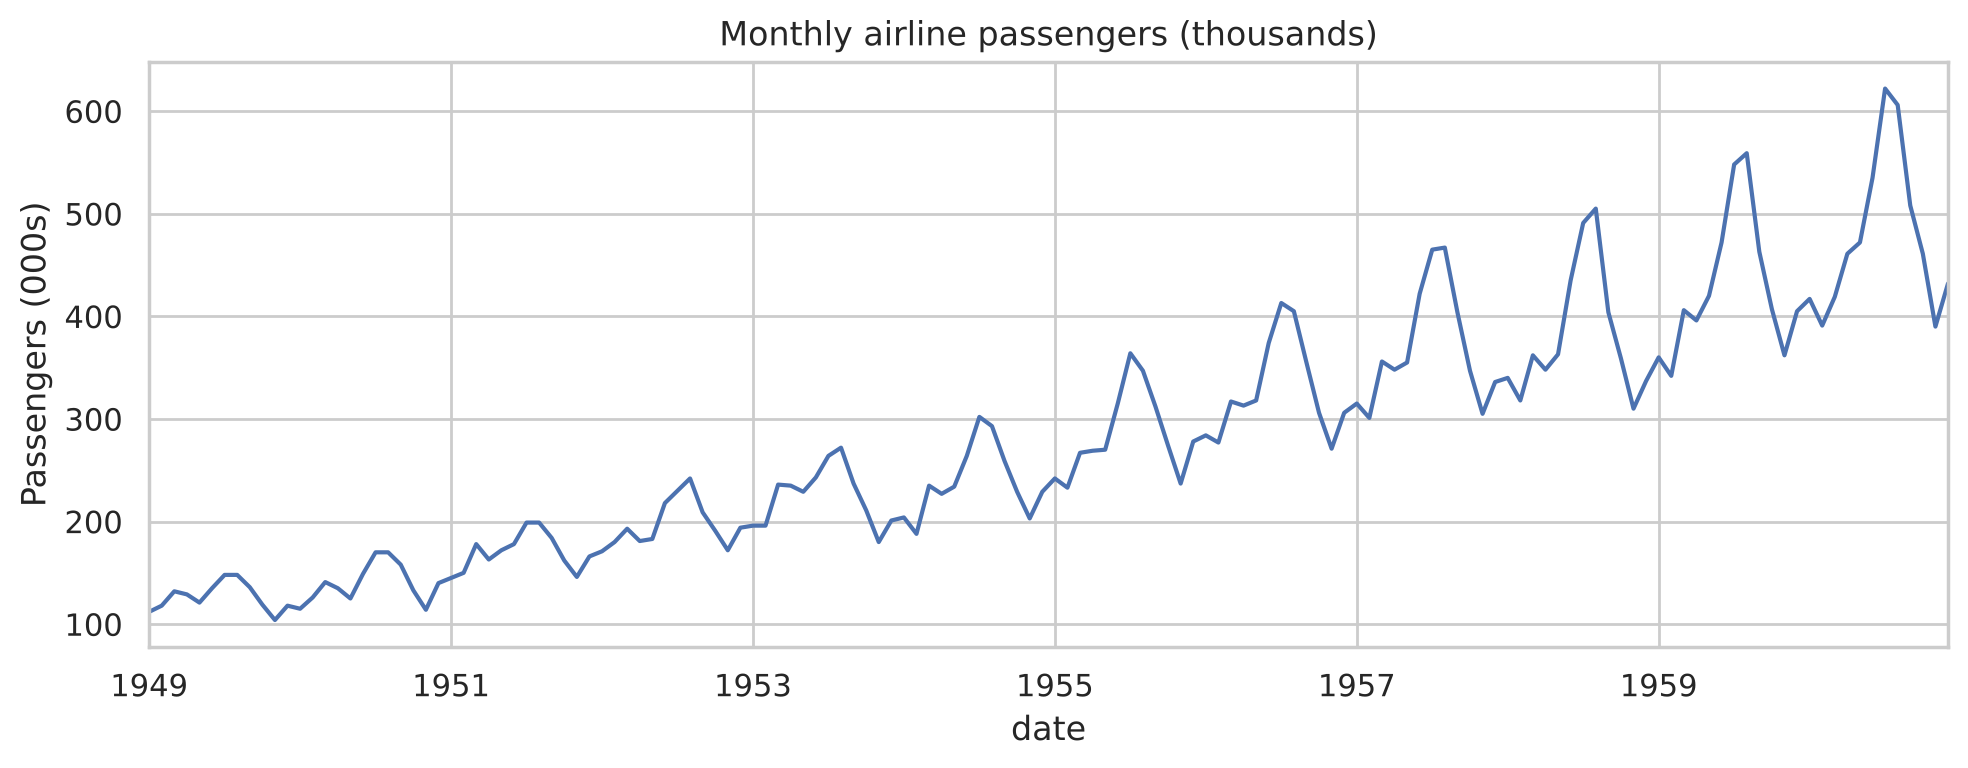

In [3]:
ax = ts.plot(figsize=(10, 4), title="Monthly airline passengers (thousands)")
ax.set_ylabel("Passengers (000s)")
savefig("series")

Two clear patterns: an upward **trend**, and a yearly **seasonality** whose size grows with the level → this suggests a **multiplicative** structure (a log transform will make it additive).

## 2. Decomposition

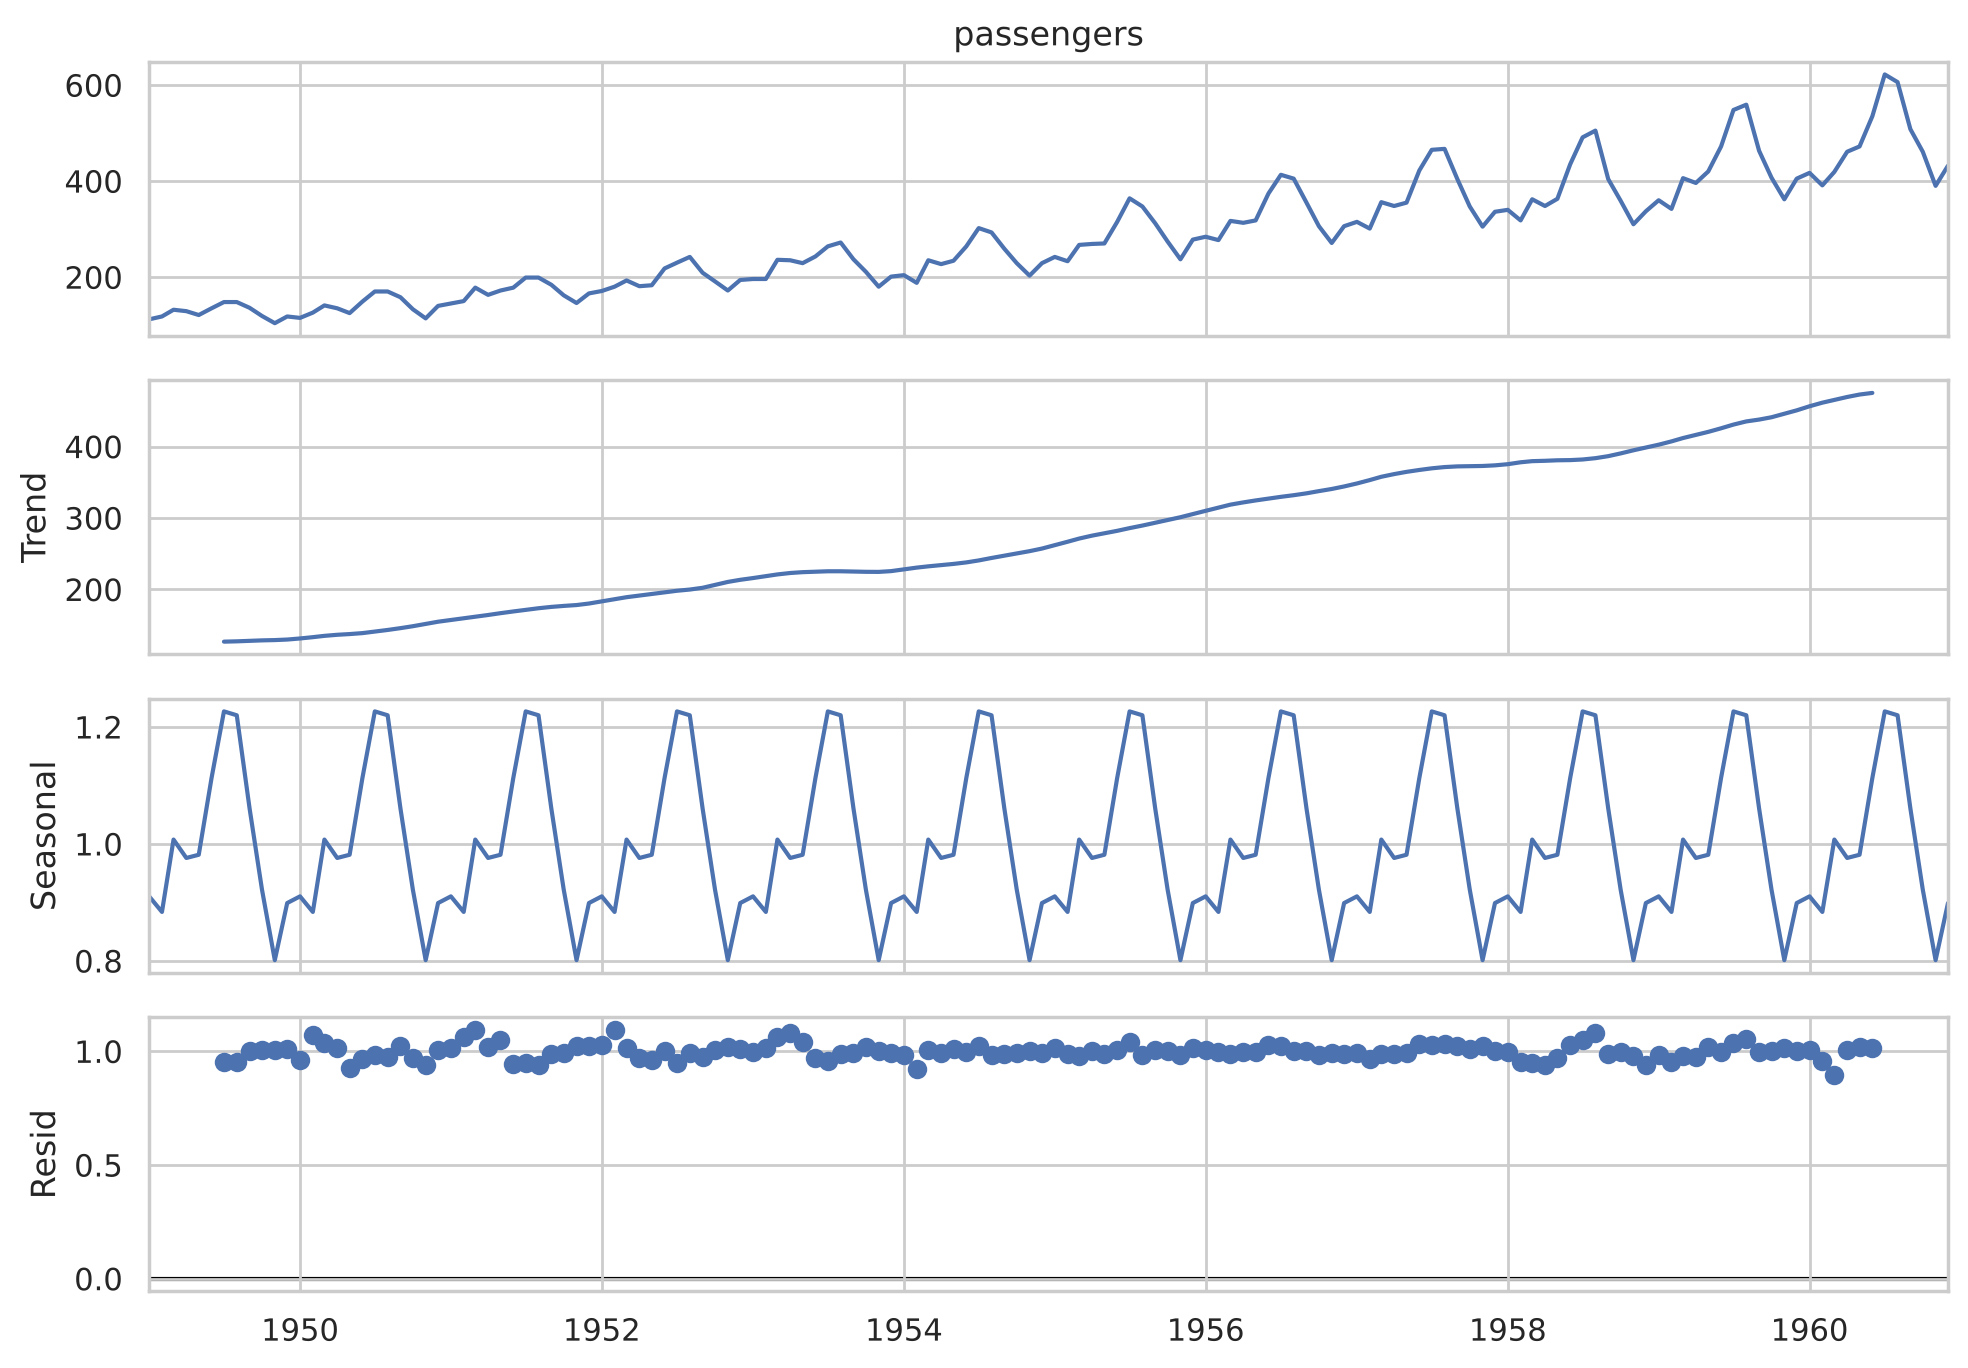

In [4]:
dec = seasonal_decompose(ts, model="multiplicative")
fig = dec.plot(); fig.set_size_inches(10, 7)
savefig("decomposition")

In [5]:
season = dec.seasonal["1949"]
season.index = season.index.strftime("%b")
(season.round(3) - 1).mul(100).round(1).rename("% vs average month")

date
Jan    -9.0
Feb   -11.6
Mar     0.7
Apr    -2.4
May    -1.9
Jun    11.3
Jul    22.7
Aug    22.0
Sep     6.0
Oct    -7.8
Nov   -19.9
Dec   -10.1
Name: % vs average month, dtype: float64

July and August are ~20 % above an average month; November is ~20 % below.

## 3. Stationarity (Augmented Dickey-Fuller test)
ARIMA-type models need a **stationary** series (constant mean and variance). The ADF test's null hypothesis is *"the series is NOT stationary"*, so we want p < 0.05.

In [6]:
def adf(series, name):
    stat, p, *_ = adfuller(series.dropna())
    return {"series": name, "ADF statistic": round(stat, 3), "p-value": round(p, 4), "stationary?": p < 0.05}

log_ts = np.log(ts)
pd.DataFrame([adf(ts, "original"),
              adf(log_ts, "log"),
              adf(log_ts.diff(), "log + 1st difference"),
              adf(log_ts.diff().diff(12), "log + 1st + seasonal (12) difference")])

,series,ADF statistic,p-value,stationary?
0,original,0.815,0.9919,False
1,log,-1.717,0.4224,False
2,log + 1st difference,-2.717,0.0711,False
3,log + 1st + seasonal (12) difference,-4.443,0.0002,True


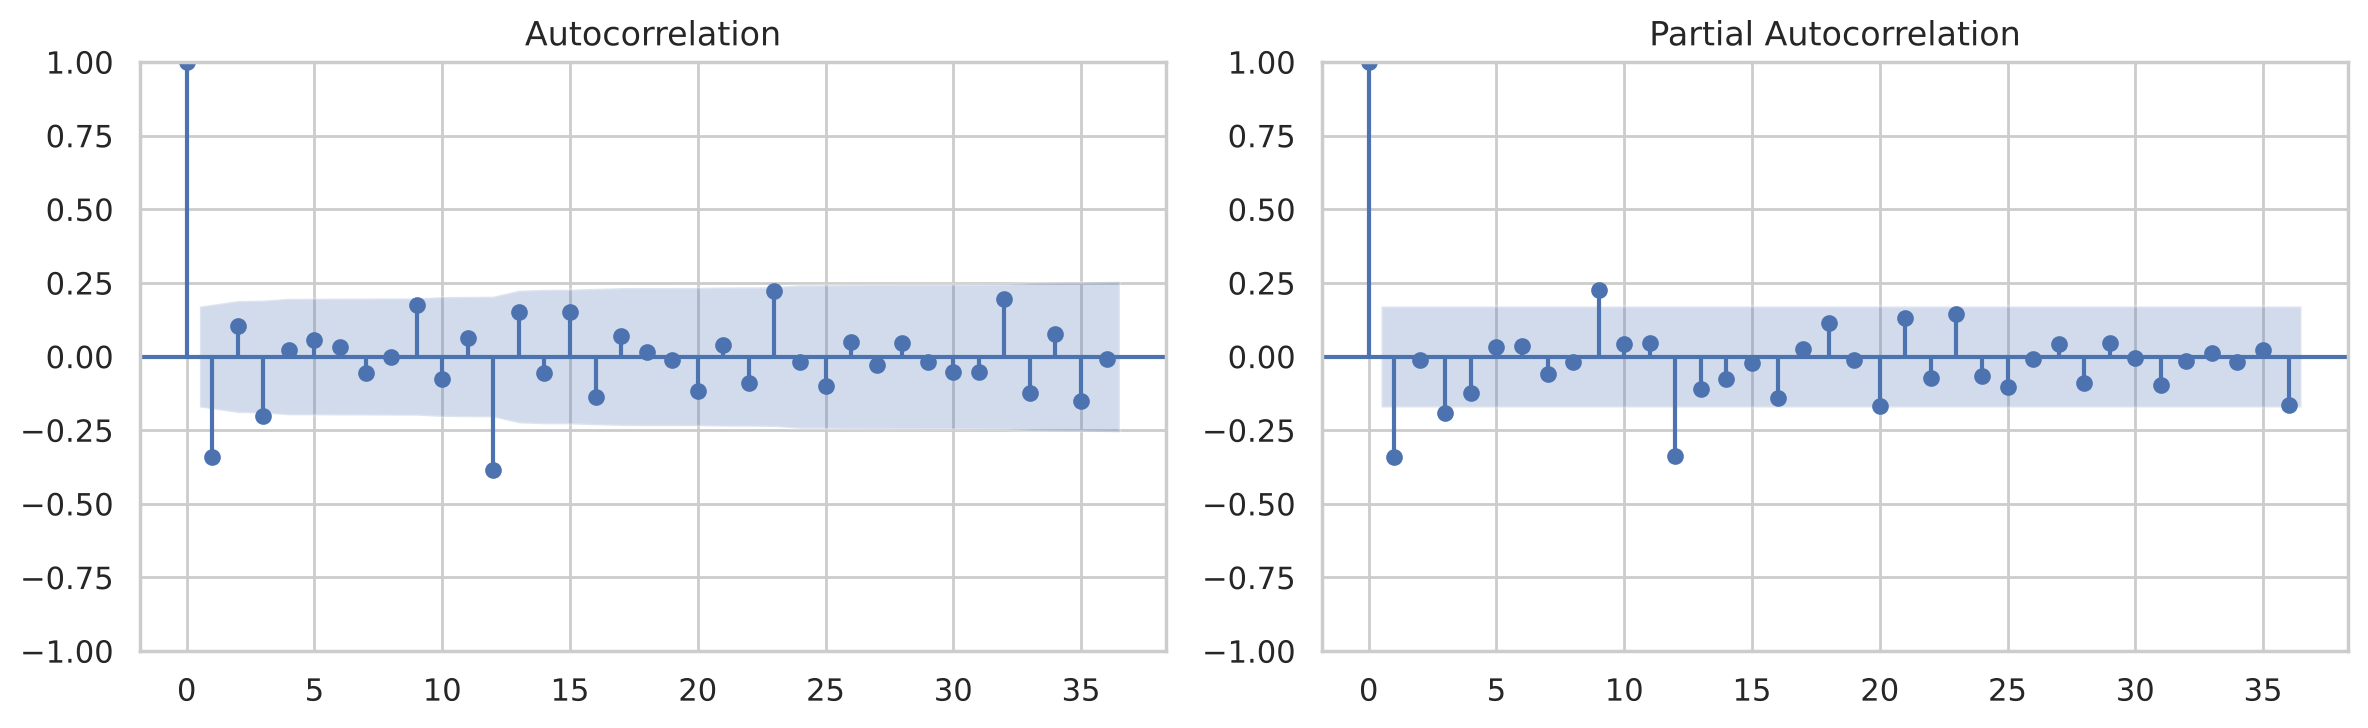

In [7]:
stationary = log_ts.diff().diff(12).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(stationary, lags=36, ax=axes[0]); plot_pacf(stationary, lags=36, ax=axes[1], method="ywm")
savefig("acf_pacf")

After log + regular + seasonal differencing the series is stationary. Significant spikes at lag 1 and lag 12 in the ACF point to the famous **"airline model" SARIMA(0,1,1)(0,1,1)₁₂**.

## 4. Train/test split
Hold out the last **24 months (1959–1960)** as the test set. The models never see these values.

In [8]:
train, test = ts[:-24], ts[-24:]
h = len(test)

def scores(actual, pred):
    rmse = np.sqrt(np.mean((actual - pred) ** 2))
    mape = np.mean(np.abs((actual - pred) / actual)) * 100
    return round(rmse, 1), round(mape, 2)

## 5. Models
### Baselines
A forecast is only good if it beats simple rules: **naive** (repeat last value) and **seasonal naive** (repeat the value from the same month last year).

In [9]:
forecasts = {}
forecasts["Naive"] = pd.Series(train.iloc[-1], index=test.index)
forecasts["Seasonal naive"] = pd.Series(np.tile(train[-12:].values, 2), index=test.index)

### Holt-Winters exponential smoothing
Models level, trend and multiplicative seasonality with exponentially decaying weights.

In [10]:
hw = ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12).fit()
forecasts["Holt-Winters"] = hw.forecast(h)

### SARIMA (0,1,1)(0,1,1)₁₂ on log scale

In [11]:
sarima = SARIMAX(np.log(train), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sarima.summary().tables[1])
fc = sarima.get_forecast(h)
forecasts["SARIMA"] = np.exp(fc.predicted_mean)
ci = np.exp(fc.conf_int())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3425      0.087     -3.923      0.000      -0.514      -0.171
ma.S.L12      -0.5407      0.105     -5.157      0.000      -0.746      -0.335
sigma2         0.0014      0.000      7.865      0.000       0.001       0.002


## 6. Evaluation

In [12]:
results = pd.DataFrame({name: scores(test, f) for name, f in forecasts.items()}, index=["RMSE", "MAPE %"]).T
results.sort_values("RMSE")

,RMSE,MAPE %
Holt-Winters,32.5,6.39
SARIMA,43.2,8.51
Seasonal naive,77.0,15.52
Naive,137.3,23.58


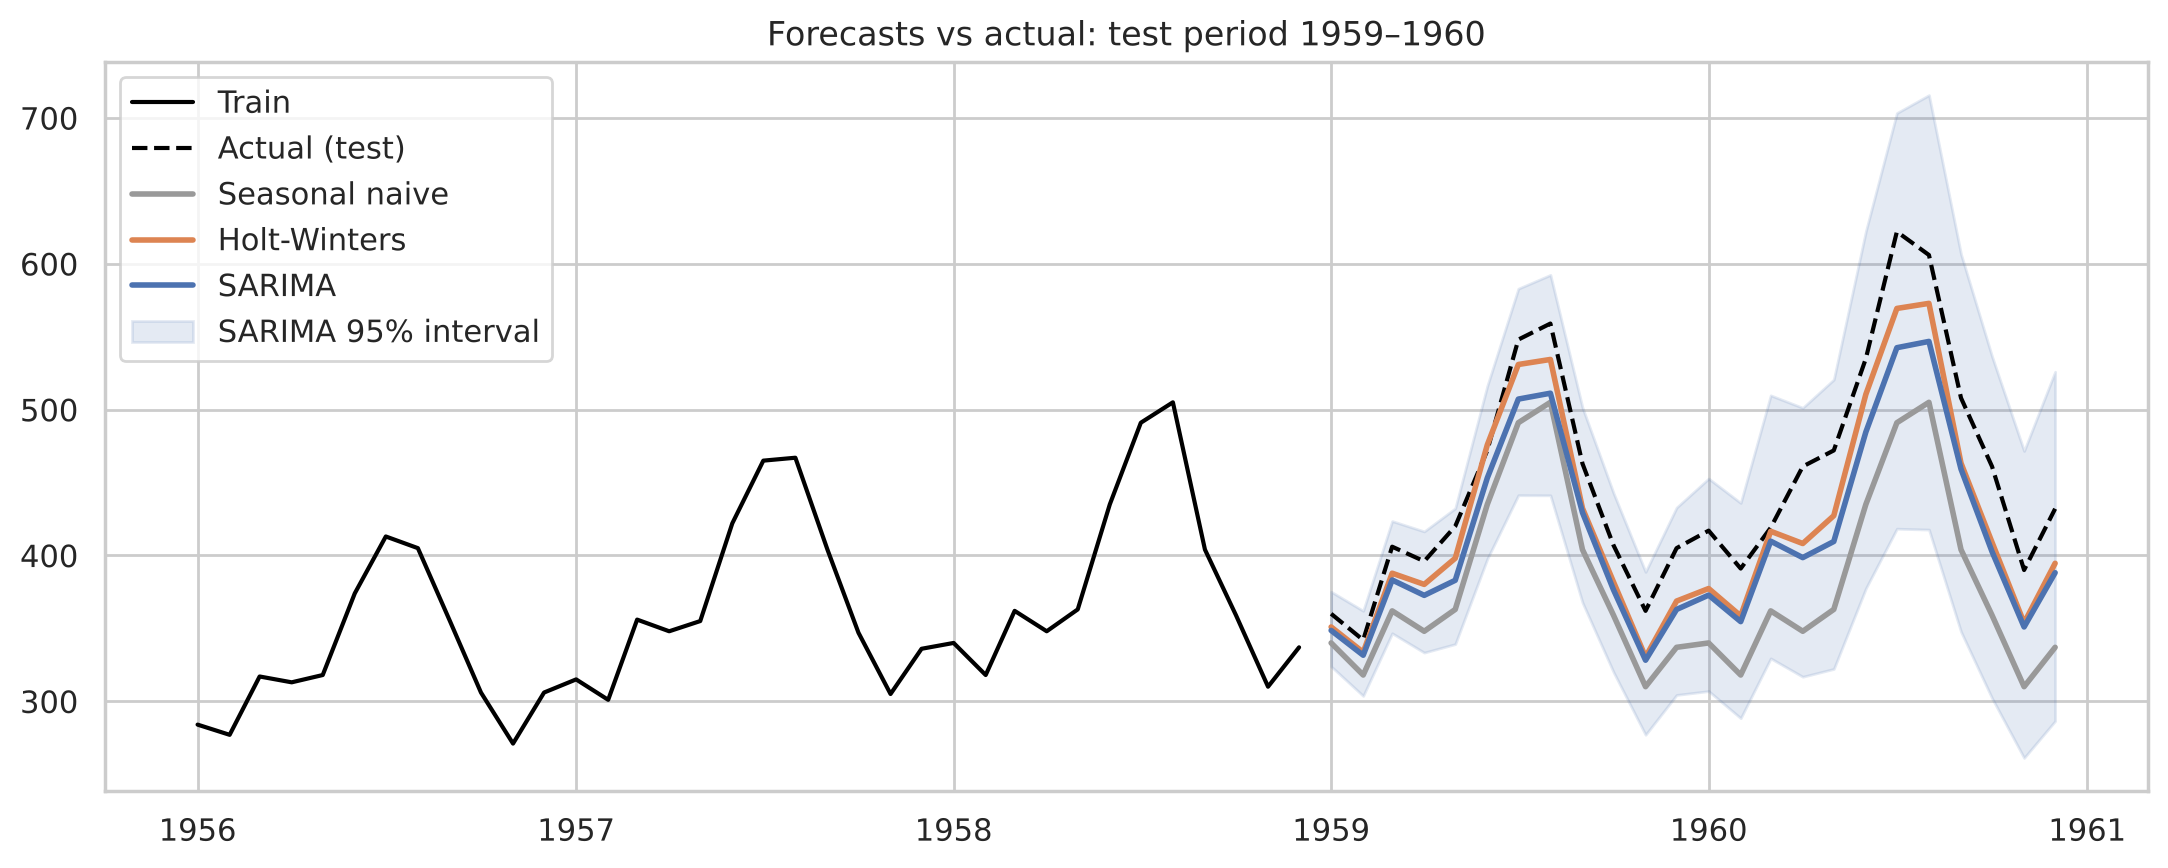

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(train["1956":], label="Train", color="black")
ax.plot(test, label="Actual (test)", color="black", ls="--")
for name, c in [("Seasonal naive", "#999999"), ("Holt-Winters", "#DD8452"), ("SARIMA", "#4C72B0")]:
    ax.plot(forecasts[name], label=name, color=c, lw=2)
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="#4C72B0", alpha=.15, label="SARIMA 95% interval")
ax.set_title("Forecasts vs actual: test period 1959–1960"); ax.legend(loc="upper left")
savefig("forecast_comparison")

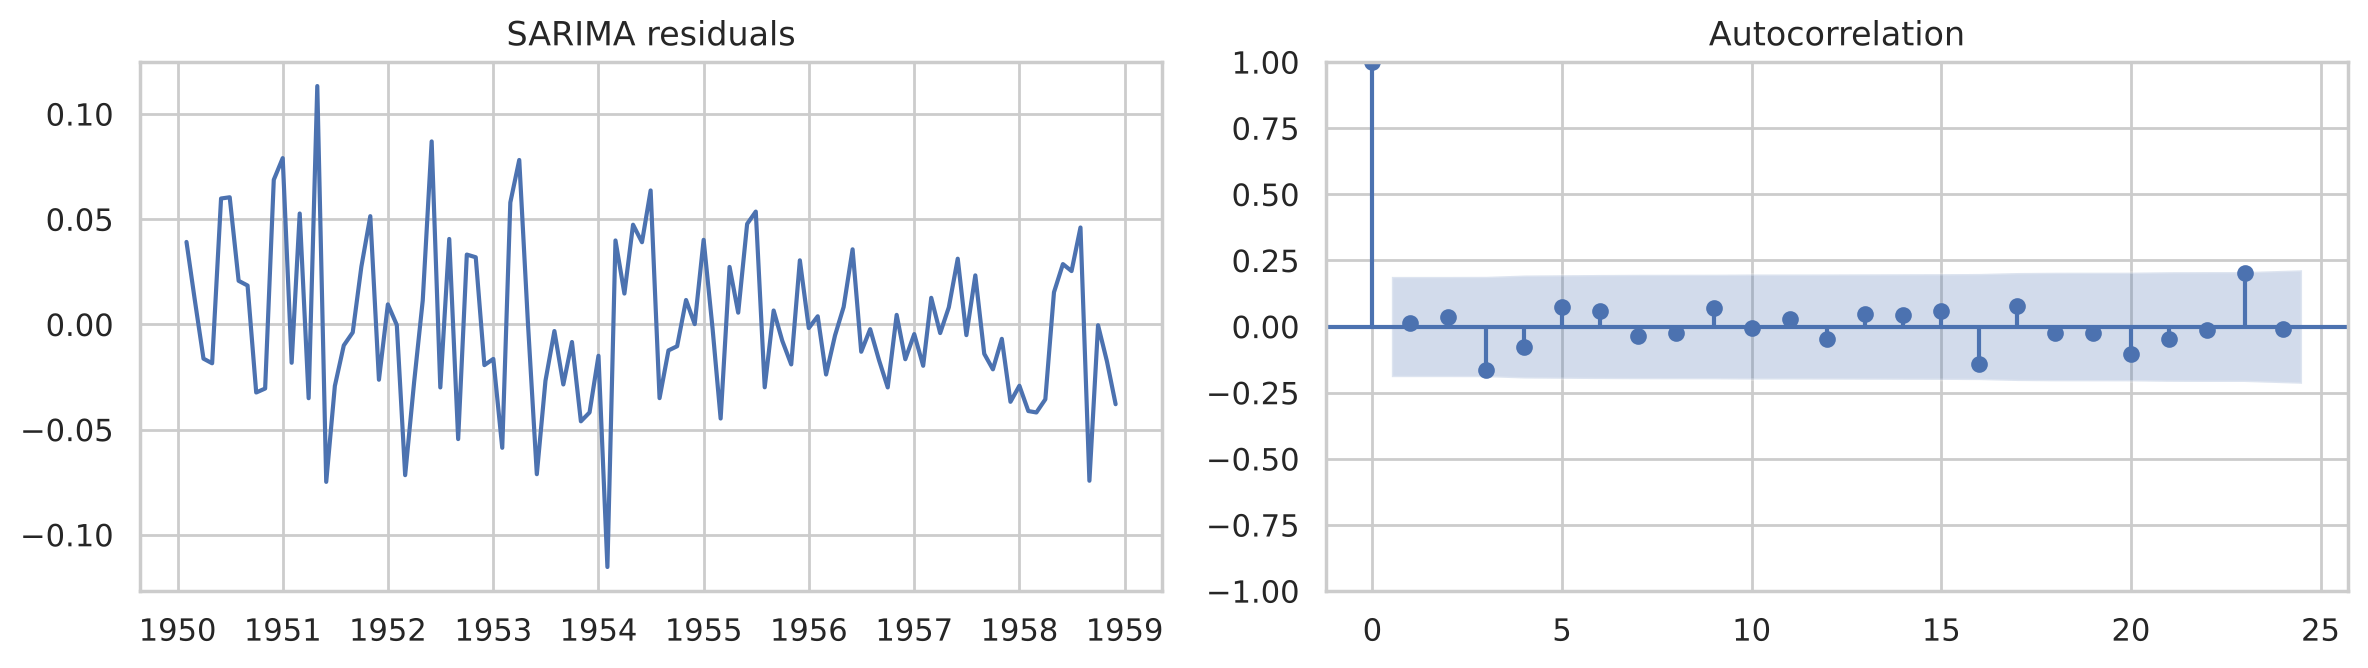

In [14]:
# Residual check: good residuals look like random noise
resid = sarima.resid[13:]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(resid); axes[0].set_title("SARIMA residuals")
plot_acf(resid, lags=24, ax=axes[1])
savefig("residuals")

## 7. Forecast the future
Refit SARIMA on **all** data and forecast 1961–1962.

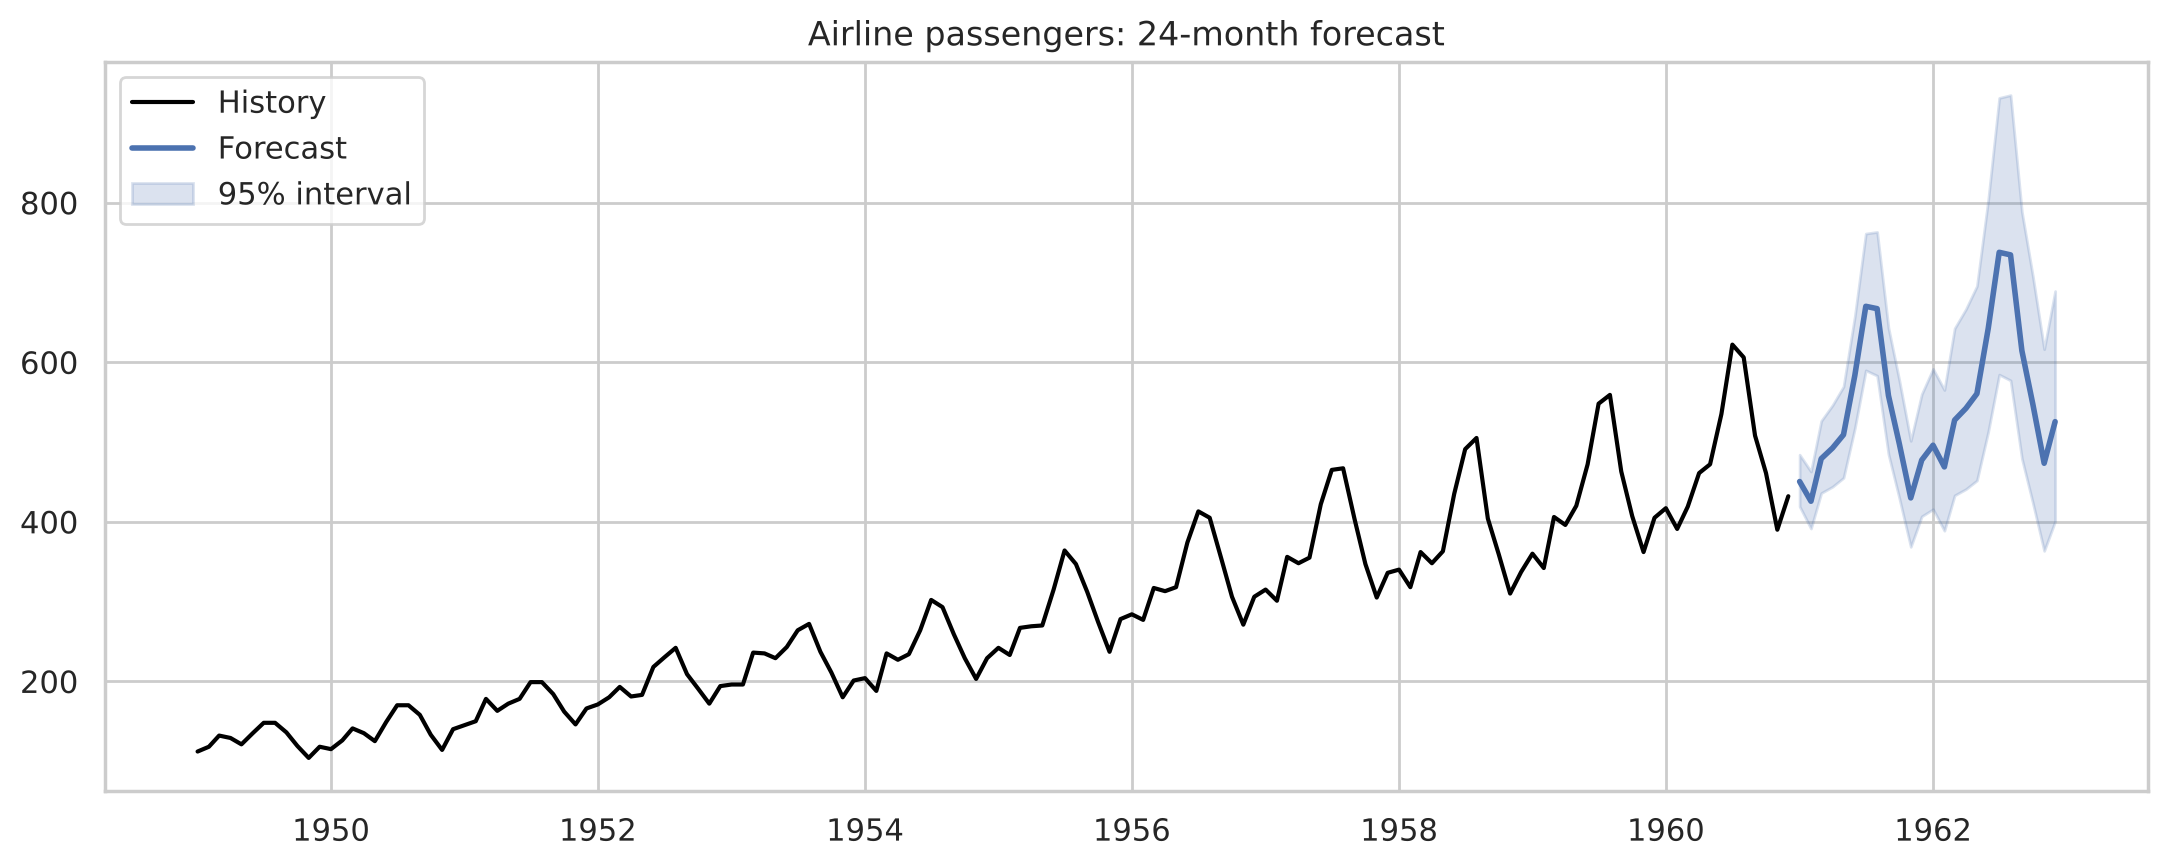

1961-01-01    450.0
1961-02-01    426.0
1961-03-01    479.0
1961-04-01    492.0
1961-05-01    509.0
1961-06-01    583.0
1961-07-01    670.0
1961-08-01    667.0
1961-09-01    558.0
1961-10-01    497.0
1961-11-01    430.0
1961-12-01    477.0
Freq: MS, Name: predicted_mean, dtype: float64

In [15]:
final = SARIMAX(np.log(ts), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
fut = final.get_forecast(24)
mean_f, ci_f = np.exp(fut.predicted_mean), np.exp(fut.conf_int())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ts, color="black", label="History")
ax.plot(mean_f, color="#4C72B0", lw=2, label="Forecast")
ax.fill_between(ci_f.index, ci_f.iloc[:, 0], ci_f.iloc[:, 1], color="#4C72B0", alpha=.2, label="95% interval")
ax.set_title("Airline passengers: 24-month forecast"); ax.legend(loc="upper left")
savefig("future_forecast")
mean_f.round(0).head(12)

## Conclusions

- The series has a strong trend and **multiplicative** yearly seasonality; a log transform turns it into an additive structure.
- Both models clearly beat the baselines on the unseen 1959–60 data: **Holt-Winters** was most accurate (MAPE ≈ 6.4 %), **SARIMA** close behind (≈ 8.5 %), vs 15.5 % for the seasonal naive forecast.
- SARIMA residuals behave like white noise, so the model captures the structure well.
- Forecast uncertainty widens with the horizon, as it should.

**Skills shown:** decomposition, stationarity testing (ADF), ACF/PACF interpretation, SARIMA and exponential smoothing, proper out-of-sample evaluation against baselines.